# DL PR 4 · Project A — CNN from Scratch (CIFAR-10 Image Classifier)

## Task A1: Data Loading, EDA & Preprocessing

### A1.1 Load CIFAR-10

In [1]:
import tensorflow as tf
import tf_keras as keras

import os
import pickle
import zipfile
import numpy as np


In [2]:
tf.get_logger().setLevel('ERROR')

In [3]:
data_dir = 'cifar-10-batches-py'

In [4]:
if not os.path.exists(data_dir):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('.')

In [5]:
def load_batch(file_path):
    with open(file_path, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')
    images = batch[b'data'].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)
    labels = np.array(batch[b'labels'])
    return images, labels

In [6]:
X_list = []
y_list = []

for i in range(1, 6):
    images, labels = load_batch(os.path.join(data_dir, f'data_batch_{i}'))
    X_list.append(images)
    y_list.append(labels)

In [7]:
X_train = np.concatenate(X_list)
y_train = np.concatenate(y_list).reshape(-1, 1)

In [8]:
X_test, y_test = load_batch(os.path.join(data_dir, 'test_batch'))
y_test = y_test.reshape(-1, 1)

In [9]:
# (X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

In [10]:
import numpy as np

In [11]:
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)

In [12]:
print('X_train:', X_train.shape)
print('y_train:', y_train.shape)

X_train: (50000, 32, 32, 3)
y_train: (50000, 1)


In [13]:
print('X_test :', X_test.shape)
print('y_test :', y_test.shape)

X_test : (10000, 32, 32, 3)
y_test : (10000, 1)


In [14]:
print('Unique labels:', np.unique(y_train))

Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [15]:
print('Image dtype:', X_train.dtype)

Image dtype: uint8


In [16]:
input_shape = X_train.shape[1:]
print('Input shape:', input_shape)

Input shape: (32, 32, 3)


### A1.2 Visualise sample images

In [17]:
import os
import matplotlib.pyplot as plt

In [18]:
plots_dir = 'plots'
os.makedirs(plots_dir, exist_ok=True)

In [19]:
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
num_classes = len(class_names)

In [20]:
samples_per_class = 5

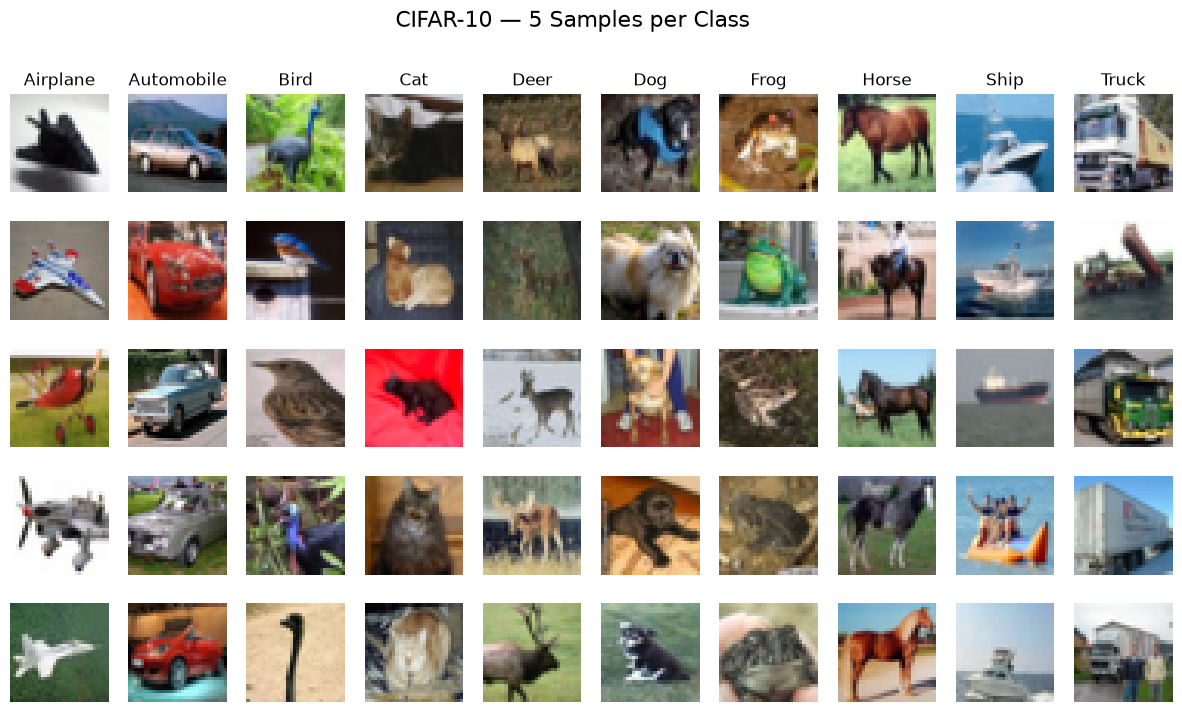

In [21]:
fig, axes = plt.subplots(samples_per_class, num_classes, figsize=(15, 8))

for class_id in range(num_classes):
    class_images = X_train[y_train.flatten() == class_id][:samples_per_class]
    axes[0, class_id].set_title(class_names[class_id])
    for row in range(samples_per_class):
        axes[row, class_id].imshow(class_images[row])
        axes[row, class_id].axis('off')

fig.suptitle(f'CIFAR-10 — {samples_per_class} Samples per Class', fontsize=16)
plt.savefig(plots_dir + '/sample_grid.png', bbox_inches='tight')
plt.show()

- Cat and dog look very similar.
- Automobile and truck look very similar.
- These pairs will be the hardest for the CNN.

### A1.3 Pixel distribution and normalisation

In [22]:
n_images = 1000
pixels_before = X_train[:n_images].flatten()

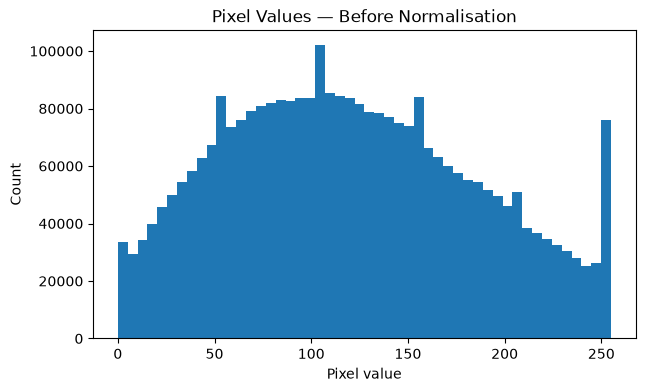

In [23]:
plt.figure(figsize=(7, 4))
plt.hist(pixels_before, bins=50)
plt.title('Pixel Values — Before Normalisation')
plt.xlabel('Pixel value')
plt.ylabel('Count')
plt.savefig(plots_dir + '/pixel_hist_before.png', bbox_inches='tight')
plt.show()

In [24]:
max_pixel = X_train.max()
print('Maximum pixel value:', max_pixel)

Maximum pixel value: 255


In [25]:
X_train = X_train.astype('float32') / max_pixel
X_test = X_test.astype('float32') / max_pixel

In [26]:
print('Min:', X_train.min())
print('Max:', X_train.max())

Min: 0.0
Max: 1.0


In [27]:
pixels_after = X_train[:n_images].flatten()

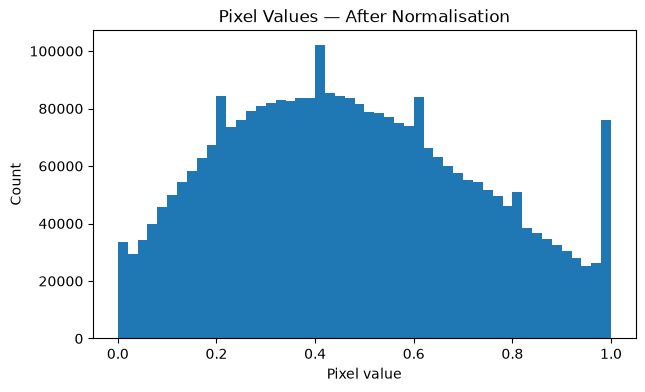

In [28]:
plt.figure(figsize=(7, 4))
plt.hist(pixels_after, bins=50)
plt.title('Pixel Values — After Normalisation')
plt.xlabel('Pixel value')
plt.ylabel('Count')
plt.savefig(plots_dir + '/pixel_hist_after.png', bbox_inches='tight')
plt.show()

- Before: pixel values go from 0 to the maximum pixel value.
- After: pixel values go from 0 to 1.
- Small input values help the model train faster and more stable.

### A1.4 One-hot encode labels

In [29]:
y_train_ohe = keras.utils.to_categorical(y_train, num_classes)
y_test_ohe = keras.utils.to_categorical(y_test, num_classes)

In [30]:
print('y_train_ohe:', y_train_ohe.shape)
print('y_test_ohe :', y_test_ohe.shape)

y_train_ohe: (50000, 10)
y_test_ohe : (10000, 10)


### A1.5 Train / validation split

In [31]:
val_split = 0.1
val_size = int(len(X_train) * val_split)

In [32]:
X_tr = X_train[:-val_size]
y_tr = y_train_ohe[:-val_size]

In [33]:
X_val = X_train[-val_size:]
y_val = y_train_ohe[-val_size:]

In [34]:
print('Train     :', X_tr.shape)
print('Validation:', X_val.shape)

Train     : (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)


### A1.6 CNN vs ANN — parameter count

In [35]:
units = 8
kernel_size = 3

In [36]:
mlp_demo = keras.Sequential([
    keras.layers.Flatten(input_shape=input_shape),
    keras.layers.Dense(units)
])

In [37]:
cnn_demo = keras.Sequential([
    keras.layers.Conv2D(units, kernel_size, input_shape=input_shape)
])

In [38]:
print('MLP (Dense) parameters:', mlp_demo.count_params())
print('CNN (Conv2D) parameters:', cnn_demo.count_params())

MLP (Dense) parameters: 24584
CNN (Conv2D) parameters: 224


- The MLP flattens the image, so it loses the position of pixels.
- The CNN uses one small filter on the whole image (shared weights).
- CNN needs far fewer parameters for the same number of outputs.

## Task A2: Convolution Operation, Padding & Strides

### A2.1 Manual convolution

In [39]:
from scipy.signal import convolve2d

In [40]:
image_index = 0
gray = np.mean(X_train[image_index], axis=2)

In [41]:
edge_kernel = np.array([[-1, -1, -1],
                        [-1,  8, -1],
                        [-1, -1, -1]])

In [42]:
conv_output = convolve2d(gray, edge_kernel, mode='valid')

In [43]:
print('Greyscale image:', gray.shape)
print('Convolved image:', conv_output.shape)

Greyscale image: (32, 32)
Convolved image: (30, 30)


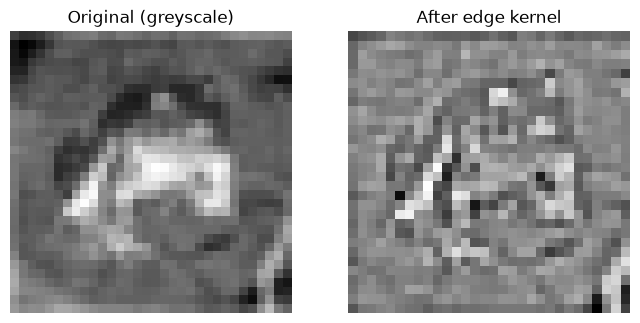

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Original (greyscale)')
axes[1].imshow(conv_output, cmap='gray')
axes[1].set_title('After edge kernel')

for ax in axes:
    ax.axis('off')

plt.savefig(plots_dir + '/manual_convolution.png', bbox_inches='tight')
plt.show()

- The kernel slides over the image and gives one value for each patch.
- The edge kernel keeps the edges and removes the flat areas.
- With no padding, the output is smaller than the input.

### A2.2 Padding — VALID vs SAME

In [45]:
test_image = X_train[image_index:image_index + 1]

In [46]:
filters = 8
stride = 1

In [47]:
model_valid = keras.Sequential([
    keras.layers.Conv2D(filters, kernel_size, strides=stride,
                        padding='valid', input_shape=input_shape)
])

In [48]:
print('VALID output shape:', model_valid.output_shape)

VALID output shape: (None, 30, 30, 8)


In [49]:
expected_size = (input_shape[0] - kernel_size) // stride + 1
print('Formula: (input - kernel) / stride + 1 =', expected_size)

Formula: (input - kernel) / stride + 1 = 30


In [50]:
model_same = keras.Sequential([
    keras.layers.Conv2D(filters, kernel_size, strides=stride,
                        padding='same', input_shape=input_shape)
])

In [51]:
print('SAME output shape:', model_same.output_shape)

SAME output shape: (None, 32, 32, 8)


In [52]:
pad = kernel_size // 2
padded_image = np.pad(test_image[0], ((pad, pad), (pad, pad), (0, 0)))

In [53]:
print('Original image:', test_image[0].shape)
print('Padded image  :', padded_image.shape)

Original image: (32, 32, 3)
Padded image  : (34, 34, 3)


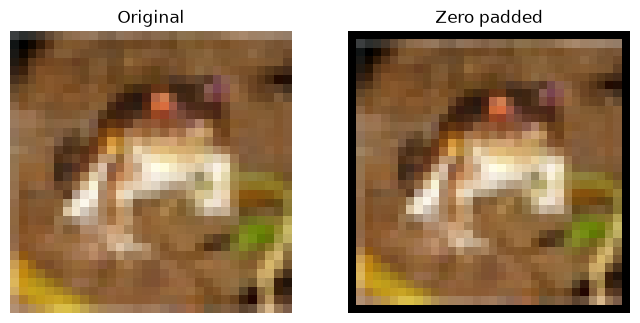

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(test_image[0])
axes[0].set_title('Original')
axes[1].imshow(padded_image)
axes[1].set_title('Zero padded')

for ax in axes:
    ax.axis('off')

plt.savefig(plots_dir + '/zero_padding.png', bbox_inches='tight')
plt.show()

- VALID padding makes the output smaller.
- SAME padding keeps the output size equal to the input size.
- SAME is used in most CNNs so many layers can be stacked.

### A2.3 Strides effect

In [55]:
paddings = ['valid', 'same']
strides = [1, 2]

In [56]:
for padding in paddings:
    for s in strides:
        model = keras.Sequential([
            keras.layers.Conv2D(filters, kernel_size, strides=s,
                                padding=padding, input_shape=input_shape)
        ])
        height, width = model.output_shape[1:3]
        print(f'padding = {padding:5s} | stride = {s} -> {height} x {width}')

padding = valid | stride = 1 -> 30 x 30
padding = valid | stride = 2 -> 15 x 15
padding = same  | stride = 1 -> 32 x 32
padding = same  | stride = 2 -> 16 x 16


- Stride 1 keeps dense feature maps.
- A bigger stride makes the height and width smaller.

### A2.4 Feature maps

In [57]:
feature_filters = 16
grid_size = int(np.sqrt(feature_filters))

In [58]:
model_vis = keras.Sequential([
    keras.layers.Conv2D(feature_filters, kernel_size, activation='relu',
                        padding='same', input_shape=input_shape)
])

In [59]:
maps_conv = model_vis.predict(test_image, verbose=0)
print('Feature maps shape:', maps_conv.shape)

Feature maps shape: (1, 32, 32, 16)


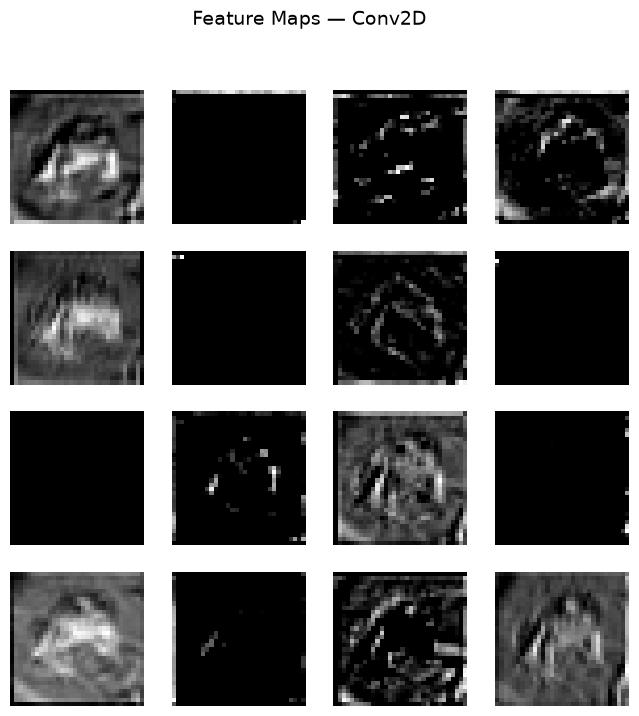

In [60]:
fig, axes = plt.subplots(grid_size, grid_size, figsize=(8, 8))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(maps_conv[0, :, :, i], cmap='gray')
    ax.axis('off')

fig.suptitle('Feature Maps — Conv2D', fontsize=14)
plt.savefig(plots_dir + '/feature_maps.png', bbox_inches='tight')
plt.show()

- Each map shows what one filter finds in the image.
- Early filters find edges, colours and simple patterns.

## Task A3: Pooling, Flatten & CNN Architecture

### A3.1 MaxPooling vs AveragePooling

In [61]:
pool_size = 2

In [62]:
model_max = keras.Sequential([model_vis, keras.layers.MaxPooling2D(pool_size)])
maps_max = model_max.predict(test_image, verbose=0)

In [63]:
model_avg = keras.Sequential([model_vis, keras.layers.AveragePooling2D(pool_size)])
maps_avg = model_avg.predict(test_image, verbose=0)

In [64]:
print('Before pooling      :', maps_conv.shape)
print('After MaxPooling    :', maps_max.shape)
print('After AveragePooling:', maps_avg.shape)

Before pooling      : (1, 32, 32, 16)
After MaxPooling    : (1, 16, 16, 16)
After AveragePooling: (1, 16, 16, 16)


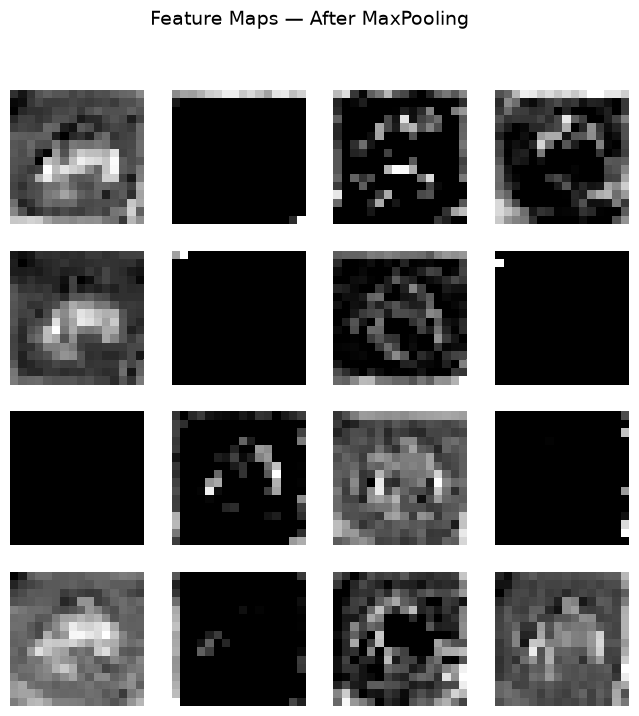

In [65]:
fig, axes = plt.subplots(grid_size, grid_size, figsize=(8, 8))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(maps_max[0, :, :, i], cmap='gray')
    ax.axis('off')

fig.suptitle('Feature Maps — After MaxPooling', fontsize=14)
plt.savefig(plots_dir + '/feature_maps_maxpool.png', bbox_inches='tight')
plt.show()

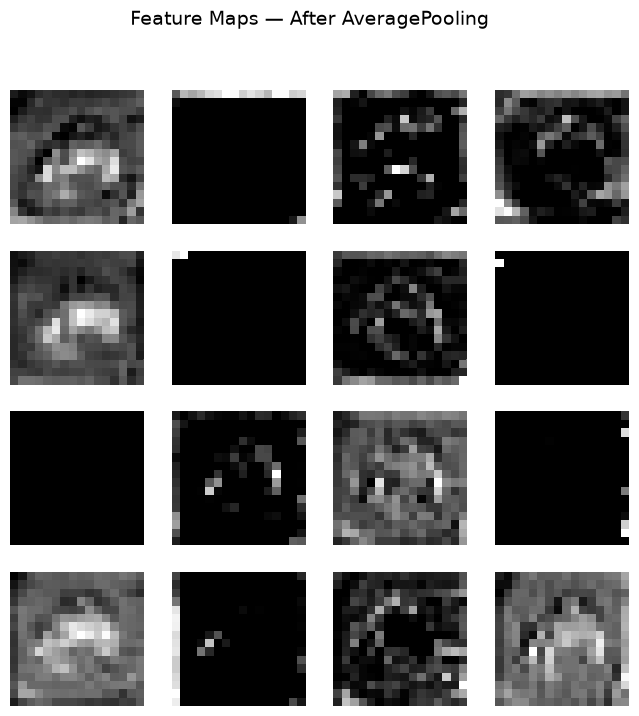

In [66]:
fig, axes = plt.subplots(grid_size, grid_size, figsize=(8, 8))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(maps_avg[0, :, :, i], cmap='gray')
    ax.axis('off')

fig.suptitle('Feature Maps — After AveragePooling', fontsize=14)
plt.savefig(plots_dir + '/feature_maps_avgpool.png', bbox_inches='tight')
plt.show()

- Both poolings make the height and width smaller.
- MaxPooling keeps the strongest value, so maps look sharper.
- AveragePooling keeps the mean value, so maps look smoother.

### A3.2 Flatten layer

In [67]:
model_flat = keras.Sequential([model_max, keras.layers.Flatten()])
flat_output = model_flat.predict(test_image, verbose=0)

In [68]:
print('Before Flatten:', maps_max.shape)
print('After Flatten :', flat_output.shape)

Before Flatten: (1, 16, 16, 16)
After Flatten : (1, 4096)


- Flatten turns the 3D maps into one long vector.
- This vector goes into the Dense layers.

### A3.3 LeNet-5

In [69]:
model_lenet = keras.Sequential([
    keras.Input(shape=input_shape),
    keras.layers.Conv2D(6, 5, activation='tanh'),
    keras.layers.AveragePooling2D(pool_size),
    keras.layers.Conv2D(16, 5, activation='tanh'),
    keras.layers.AveragePooling2D(pool_size),
    keras.layers.Flatten(),
    keras.layers.Dense(120, activation='tanh'),
    keras.layers.Dense(84, activation='tanh'),
    keras.layers.Dense(num_classes, activation='softmax')
])

In [70]:
model_lenet.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_8 (Conv2D)           (None, 28, 28, 6)         456       
                                                                 
 average_pooling2d_1 (Avera  (None, 14, 14, 6)         0         
 gePooling2D)                                                    
                                                                 
 conv2d_9 (Conv2D)           (None, 10, 10, 16)        2416      
                                                                 
 average_pooling2d_2 (Avera  (None, 5, 5, 16)          0         
 gePooling2D)                                                    
                                                                 
 flatten_2 (Flatten)         (None, 400)               0         
                                                                 
 dense_1 (Dense)             (None, 120)             

In [71]:
conv1 = model_lenet.layers[0]
manual_conv1 = (conv1.kernel_size[0] * conv1.kernel_size[1] * input_shape[2] + 1) * conv1.filters

In [72]:
print('Conv layer 1 — manual:', manual_conv1)
print('Conv layer 1 — Keras :', conv1.count_params())

Conv layer 1 — manual: 456
Conv layer 1 — Keras : 456


In [73]:
conv2 = model_lenet.layers[2]
manual_conv2 = (conv2.kernel_size[0] * conv2.kernel_size[1] * conv1.filters + 1) * conv2.filters

In [74]:
print('Conv layer 2 — manual:', manual_conv2)
print('Conv layer 2 — Keras :', conv2.count_params())

Conv layer 2 — manual: 2416
Conv layer 2 — Keras : 2416


- Manual count and Keras count are the same.
- Parameters per conv layer = (kernel height × kernel width × input channels + 1) × filters.

In [75]:
model_lenet.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])

In [76]:
patience = 10
lr_patience = 5

In [77]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss',
                                           patience=patience,
                                           restore_best_weights=True)

In [78]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                              factor=0.5,
                                              patience=lr_patience,
                                              min_lr=1e-6,
                                              verbose=1)

In [79]:
epochs = 100
batch_size = 64

In [80]:
history_lenet = model_lenet.fit(X_tr, y_tr,
                                epochs=epochs,
                                batch_size=batch_size,
                                validation_data=(X_val, y_val),
                                callbacks=[early_stop, reduce_lr],
                                verbose=2)

Epoch 1/100
704/704 - 2s - loss: 1.8291 - accuracy: 0.3539 - val_loss: 1.7737 - val_accuracy: 0.3720 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 2/100
704/704 - 2s - loss: 1.6271 - accuracy: 0.4262 - val_loss: 1.5803 - val_accuracy: 0.4374 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 3/100
704/704 - 2s - loss: 1.4862 - accuracy: 0.4712 - val_loss: 1.4757 - val_accuracy: 0.4764 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 4/100
704/704 - 2s - loss: 1.3967 - accuracy: 0.5058 - val_loss: 1.4137 - val_accuracy: 0.4974 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 5/100
704/704 - 2s - loss: 1.3298 - accuracy: 0.5294 - val_loss: 1.3600 - val_accuracy: 0.5206 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 6/100
704/704 - 2s - loss: 1.2759 - accuracy: 0.5476 - val_loss: 1.3376 - val_accuracy: 0.5262 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 7/100
704/704 - 2s - loss: 1.2290 - accuracy: 0.5637 - val_loss: 1.3405 - val_accuracy: 0.5290 - lr: 0.0010 - 2s/epoch - 3ms/step
Epoch 8/100
704/704 - 2s - loss: 1.1894 - accura

In [81]:
lenet_loss, lenet_acc = model_lenet.evaluate(X_test, y_test_ohe, verbose=0)
print(f'LeNet-5 test accuracy: {lenet_acc:.4f}')

LeNet-5 test accuracy: 0.5476


In [82]:
print('Train accuracy:', round(history_lenet.history['accuracy'][-1], 4))
print('Val accuracy  :', round(history_lenet.history['val_accuracy'][-1], 4))
print('Test accuracy :', round(lenet_acc, 4))

Train accuracy: 0.7438
Val accuracy  : 0.5542
Test accuracy : 0.5476


**LeNet-5 interpretation**
- LeNet-5 is a small and old model, so it is only our starting point.
- If train accuracy is much higher than val accuracy, the model is memorising the images.
- The next models must score higher than this to be worth using.

### A3.4 Custom CNN baseline

In [83]:
def build_cnn(augmentation=None):
    inputs = keras.Input(shape=input_shape)
    x = inputs

    if augmentation is not None:
        x = augmentation(x)

    x = keras.layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = keras.layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = keras.layers.MaxPooling2D(2)(x)

    x = keras.layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = keras.layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = keras.layers.MaxPooling2D(2)(x)

    x = keras.layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = keras.layers.GlobalAveragePooling2D()(x)

    x = keras.layers.Dense(256, activation='relu')(x)
    outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs)

In [84]:
model_cnn = build_cnn()

In [85]:
model_cnn.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d_10 (Conv2D)          (None, 32, 32, 32)        896       
                                                                 
 conv2d_11 (Conv2D)          (None, 32, 32, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 16, 16, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_12 (Conv2D)          (None, 16, 16, 64)        18496     
                                                                 
 conv2d_13 (Conv2D)          (None, 16, 16, 64)        36928     
                                                             

In [86]:
max_params = 2000000
print('Parameters:', model_cnn.count_params())
print('Less than limit:', model_cnn.count_params() < max_params)

Parameters: 175018
Less than limit: True


**Custom CNN interpretation**
- Three blocks of Conv layers find edges first, then shapes, then object parts.
- MaxPooling makes the maps smaller, so the model learns faster.
- GlobalAveragePooling is used instead of Flatten, so the parameters stay low.

## Task A4: Training the CNN

### A4.1 Compile and train

In [87]:
model_cnn.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

In [88]:
early_stop_cnn = keras.callbacks.EarlyStopping(monitor='val_loss',
                                               patience=patience,
                                               restore_best_weights=True)

In [89]:
reduce_lr_cnn = keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                  factor=0.5,
                                                  patience=lr_patience,
                                                  min_lr=1e-6,
                                                  verbose=1)

In [90]:
history_cnn = model_cnn.fit(X_tr, y_tr,
                            epochs=epochs,
                            batch_size=batch_size,
                            validation_data=(X_val, y_val),
                            callbacks=[early_stop_cnn, reduce_lr_cnn],
                            verbose=2)

Epoch 1/100
704/704 - 14s - loss: 1.7740 - accuracy: 0.3230 - val_loss: 1.4933 - val_accuracy: 0.4326 - lr: 0.0010 - 14s/epoch - 20ms/step
Epoch 2/100
704/704 - 13s - loss: 1.3831 - accuracy: 0.4872 - val_loss: 1.2618 - val_accuracy: 0.5326 - lr: 0.0010 - 13s/epoch - 19ms/step
Epoch 3/100
704/704 - 13s - loss: 1.1803 - accuracy: 0.5725 - val_loss: 1.1514 - val_accuracy: 0.5814 - lr: 0.0010 - 13s/epoch - 19ms/step
Epoch 4/100
704/704 - 13s - loss: 1.0558 - accuracy: 0.6174 - val_loss: 1.0207 - val_accuracy: 0.6424 - lr: 0.0010 - 13s/epoch - 19ms/step
Epoch 5/100
704/704 - 13s - loss: 0.9551 - accuracy: 0.6575 - val_loss: 0.9022 - val_accuracy: 0.6846 - lr: 0.0010 - 13s/epoch - 19ms/step
Epoch 6/100
704/704 - 13s - loss: 0.8738 - accuracy: 0.6891 - val_loss: 0.8974 - val_accuracy: 0.6904 - lr: 0.0010 - 13s/epoch - 19ms/step
Epoch 7/100
704/704 - 13s - loss: 0.8053 - accuracy: 0.7155 - val_loss: 0.8410 - val_accuracy: 0.7010 - lr: 0.0010 - 13s/epoch - 19ms/step
Epoch 8/100
704/704 - 14s -

### A4.2 Training curves

In [91]:
stop_epoch = early_stop_cnn.stopped_epoch
print('EarlyStopping epoch:', stop_epoch)
print('Epochs run        :', len(history_cnn.history['loss']))

EarlyStopping epoch: 23
Epochs run        : 24


In [92]:
lr_values = history_cnn.history['lr']
lr_drop_epochs = []

for i in range(1, len(lr_values)):
    if lr_values[i] < lr_values[i - 1]:
        lr_drop_epochs.append(i)

print('LR reduced at epochs:', lr_drop_epochs)

LR reduced at epochs: [19]


In [93]:
final_train_acc = history_cnn.history['accuracy'][-1]
final_val_acc = history_cnn.history['val_accuracy'][-1]

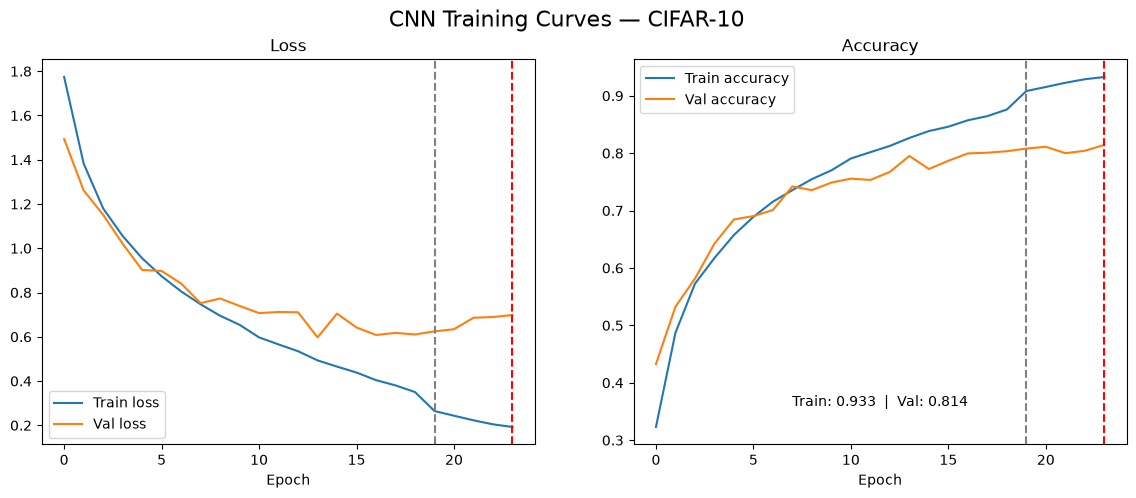

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_cnn.history['loss'], label='Train loss')
axes[0].plot(history_cnn.history['val_loss'], label='Val loss')
axes[0].set_title('Loss')

axes[1].plot(history_cnn.history['accuracy'], label='Train accuracy')
axes[1].plot(history_cnn.history['val_accuracy'], label='Val accuracy')
axes[1].set_title('Accuracy')
axes[1].text(0.5, 0.1, f'Train: {final_train_acc:.3f}  |  Val: {final_val_acc:.3f}',
             transform=axes[1].transAxes, ha='center')

for ax in axes:
    for epoch in lr_drop_epochs:
        ax.axvline(epoch, color='grey', linestyle='--')
    if stop_epoch > 0:
        ax.axvline(stop_epoch, color='red', linestyle='--')
    ax.set_xlabel('Epoch')
    ax.legend()

fig.suptitle('CNN Training Curves — CIFAR-10', fontsize=16)
plt.savefig(plots_dir + '/training_curves.png', bbox_inches='tight')
plt.show()

- Red dashed line: epoch where EarlyStopping stopped training (only if it fired).
- Grey dashed lines: epochs where the learning rate was reduced.
- A big gap between train and validation lines means overfitting.

### A4.3 Evaluate and analyse

In [95]:
test_loss, test_acc = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
print(f'Test accuracy: {test_acc:.4f}')

Test accuracy: 0.7879


In [96]:
print('Train accuracy:', round(history_cnn.history['accuracy'][-1], 4))
print('Val accuracy  :', round(history_cnn.history['val_accuracy'][-1], 4))
print('Test accuracy :', round(test_acc, 4))

Train accuracy: 0.9327
Val accuracy  : 0.8144
Test accuracy : 0.7879


**CNN result interpretation**
- Test accuracy is the real score, because the model never saw these images in training.
- If test accuracy is close to val accuracy, the model works well on new images.
- If train accuracy is much higher than test accuracy, the model is overfitting.

In [97]:
y_true = y_test.flatten()

In [98]:
y_pred_prob = model_cnn.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

In [100]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [101]:
cm = confusion_matrix(y_true, y_pred)

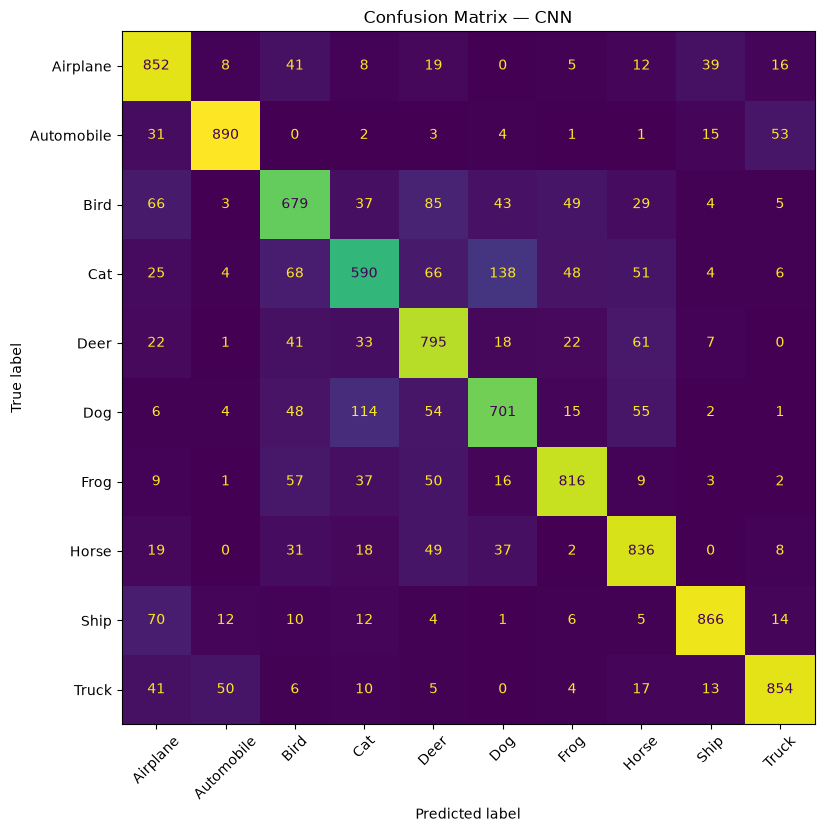

In [102]:
fig, ax = plt.subplots(figsize=(9, 9))

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, colorbar=False)

ax.set_title('Confusion Matrix — CNN')
plt.savefig(plots_dir + '/confusion_matrix.png', bbox_inches='tight')
plt.show()

**Confusion matrix interpretation**
- Rows are the true class and columns are the predicted class.
- Dark boxes on the diagonal are correct predictions.
- Dark boxes outside the diagonal are mistakes.

In [103]:
pairs = []

for i in range(num_classes):
    for j in range(i + 1, num_classes):
        mistakes = cm[i, j] + cm[j, i]
        pairs.append((mistakes, class_names[i], class_names[j]))

pairs.sort(reverse=True)

In [104]:
top_pairs = 3

print('Most confused class pairs:')
for mistakes, class_a, class_b in pairs[:top_pairs]:
    print(f'{class_a} <-> {class_b}: {mistakes} mistakes')

Most confused class pairs:
Cat <-> Dog: 252 mistakes
Bird <-> Deer: 126 mistakes
Deer <-> Horse: 110 mistakes


In [105]:
mis_rows = 2
mis_cols = 5
wrong_idx = np.where(y_pred != y_true)[0][:mis_rows * mis_cols]

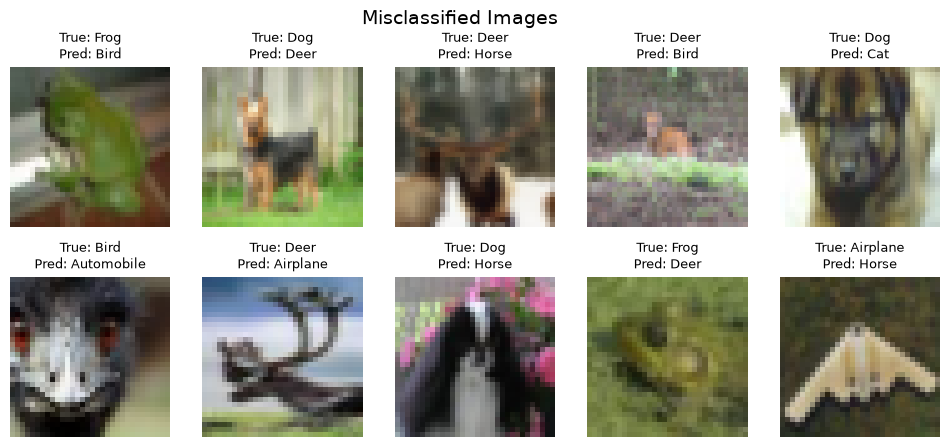

In [106]:
fig, axes = plt.subplots(mis_rows, mis_cols, figsize=(12, 5))

for ax, idx in zip(axes.flatten(), wrong_idx):
    true_name = class_names[y_true[idx]]
    pred_name = class_names[y_pred[idx]]
    ax.imshow(X_test[idx])
    ax.set_title(f'True: {true_name}\nPred: {pred_name}', fontsize=9)

for ax in axes.flatten():
    ax.axis('off')

fig.suptitle('Misclassified Images', fontsize=14)
plt.savefig(plots_dir + '/misclassified.png', bbox_inches='tight')
plt.show()

- The most confused pairs are classes that look alike.
- Images are only 32×32, so small details are lost.

In [107]:
model_cnn.save('cnn_cifar10.h5')

C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


## Task A5: Data Augmentation

### A5.1 ImageDataGenerator

In [108]:
datagen = keras.preprocessing.image.ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode='nearest'
)

In [109]:
datagen.fit(X_train)

In [110]:
sample_image = X_train[image_index]
sample_flow = datagen.flow(sample_image[np.newaxis, ...], batch_size=1)

In [111]:
aug_rows = 2
aug_cols = 5

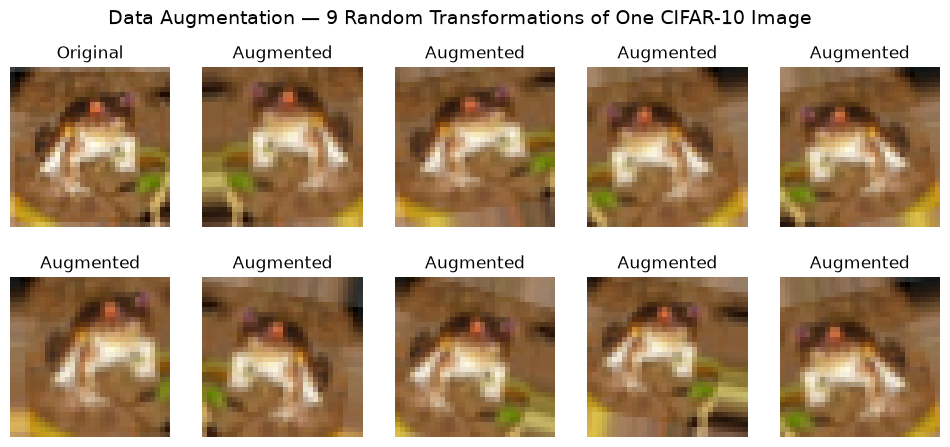

In [112]:
fig, axes = plt.subplots(aug_rows, aug_cols, figsize=(12, 5))
flat_axes = axes.flatten()

flat_axes[0].imshow(sample_image)
flat_axes[0].set_title('Original')

for ax in flat_axes[1:]:
    augmented = next(sample_flow)[0]
    ax.imshow(np.clip(augmented, 0, 1))
    ax.set_title('Augmented')

for ax in flat_axes:
    ax.axis('off')

n_augmented = aug_rows * aug_cols - 1
fig.suptitle(f'Data Augmentation — {n_augmented} Random Transformations of One CIFAR-10 Image',
             fontsize=14)
plt.savefig(plots_dir + '/augmentation_grid.png', bbox_inches='tight')
plt.show()

**Augmentation grid interpretation**
- Every picture is the same object, but turned, shifted, zoomed or flipped.
- The model sees many versions of each image, so it learns the object, not the exact pixels.
- The label stays the same, only the picture changes.

### A5.2 Retrain with ImageDataGenerator

In [113]:
model_aug = build_cnn()

In [114]:
model_aug.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

In [115]:
early_stop_aug = keras.callbacks.EarlyStopping(monitor='val_loss',
                                               patience=patience,
                                               restore_best_weights=True)

In [116]:
reduce_lr_aug = keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                  factor=0.5,
                                                  patience=lr_patience,
                                                  min_lr=1e-6,
                                                  verbose=1)

In [117]:
train_flow = datagen.flow(X_tr, y_tr, batch_size=batch_size)

In [119]:
history_aug = model_aug.fit(train_flow,
                            epochs=epochs,
                            validation_data=(X_val, y_val),
                            callbacks=[early_stop_aug, reduce_lr_aug],
                            verbose=2)

Epoch 1/100
704/704 - 17s - loss: 1.2890 - accuracy: 0.5335 - val_loss: 1.1646 - val_accuracy: 0.5804 - lr: 0.0010 - 17s/epoch - 24ms/step
Epoch 2/100
704/704 - 17s - loss: 1.1802 - accuracy: 0.5750 - val_loss: 1.1027 - val_accuracy: 0.6090 - lr: 0.0010 - 17s/epoch - 24ms/step
Epoch 3/100
704/704 - 17s - loss: 1.0980 - accuracy: 0.6060 - val_loss: 1.0064 - val_accuracy: 0.6402 - lr: 0.0010 - 17s/epoch - 25ms/step
Epoch 4/100
704/704 - 17s - loss: 1.0198 - accuracy: 0.6359 - val_loss: 0.9520 - val_accuracy: 0.6628 - lr: 0.0010 - 17s/epoch - 24ms/step
Epoch 5/100
704/704 - 17s - loss: 0.9570 - accuracy: 0.6624 - val_loss: 0.9967 - val_accuracy: 0.6684 - lr: 0.0010 - 17s/epoch - 25ms/step
Epoch 6/100
704/704 - 17s - loss: 0.9107 - accuracy: 0.6777 - val_loss: 0.8096 - val_accuracy: 0.7146 - lr: 0.0010 - 17s/epoch - 24ms/step
Epoch 7/100
704/704 - 17s - loss: 0.8597 - accuracy: 0.6976 - val_loss: 0.9476 - val_accuracy: 0.6846 - lr: 0.0010 - 17s/epoch - 24ms/step
Epoch 8/100
704/704 - 17s -

In [120]:
aug_loss, aug_acc = model_aug.evaluate(X_test, y_test_ohe, verbose=0)

In [121]:
print(f'No augmentation test accuracy  : {test_acc:.4f}')
print(f'With augmentation test accuracy: {aug_acc:.4f}')

No augmentation test accuracy  : 0.7879
With augmentation test accuracy: 0.8284


In [122]:
gap_no_aug = history_cnn.history['accuracy'][-1] - history_cnn.history['val_accuracy'][-1]
gap_aug = history_aug.history['accuracy'][-1] - history_aug.history['val_accuracy'][-1]

In [123]:
print('Train-val gap without augmentation:', round(gap_no_aug, 4))
print('Train-val gap with augmentation   :', round(gap_aug, 4))

Train-val gap without augmentation: 0.1183
Train-val gap with augmentation   : 0.0405


In [124]:
runs = {'No Aug': history_cnn, 'With Aug': history_aug}

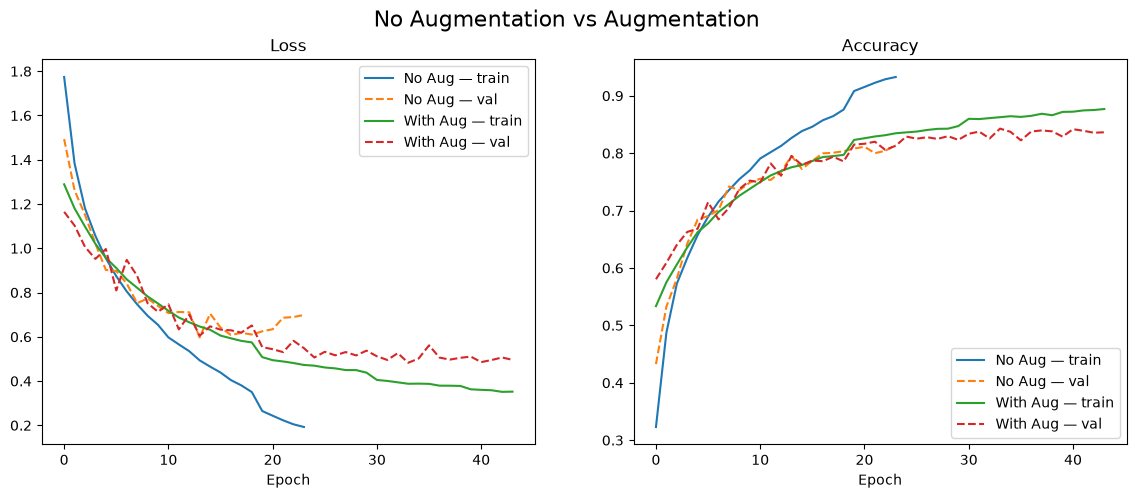

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, h in runs.items():
    axes[0].plot(h.history['loss'], label=label + ' — train')
    axes[0].plot(h.history['val_loss'], linestyle='--', label=label + ' — val')
    axes[1].plot(h.history['accuracy'], label=label + ' — train')
    axes[1].plot(h.history['val_accuracy'], linestyle='--', label=label + ' — val')

axes[0].set_title('Loss')
axes[1].set_title('Accuracy')

for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()

fig.suptitle('No Augmentation vs Augmentation', fontsize=16)
plt.savefig(plots_dir + '/augmentation_comparison.png', bbox_inches='tight')
plt.show()

- With augmentation, the gap between train and validation lines should be smaller.
- Train accuracy can be a little lower because each batch is harder.

### A5.3 Augmentation with Keras layers

In [126]:
factor = 0.1

In [127]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation(factor),
    keras.layers.RandomZoom(factor),
    keras.layers.RandomTranslation(factor, factor)
])

In [128]:
model_layers = build_cnn(augmentation=data_augmentation)

In [129]:
model_layers.compile(optimizer='adam',
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])

In [130]:
early_stop_layers = keras.callbacks.EarlyStopping(monitor='val_loss',
                                                  patience=patience,
                                                  restore_best_weights=True)

In [131]:
reduce_lr_layers = keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                     factor=0.5,
                                                     patience=lr_patience,
                                                     min_lr=1e-6,
                                                     verbose=1)

In [132]:
history_layers = model_layers.fit(X_tr, y_tr,
                                  epochs=epochs,
                                  batch_size=batch_size,
                                  validation_data=(X_val, y_val),
                                  callbacks=[early_stop_layers, reduce_lr_layers],
                                  verbose=2)

Epoch 1/100
704/704 - 16s - loss: 1.8645 - accuracy: 0.2946 - val_loss: 1.7496 - val_accuracy: 0.3624 - lr: 0.0010 - 16s/epoch - 23ms/step
Epoch 2/100
704/704 - 15s - loss: 1.5635 - accuracy: 0.4246 - val_loss: 1.5420 - val_accuracy: 0.4512 - lr: 0.0010 - 15s/epoch - 22ms/step
Epoch 3/100
704/704 - 15s - loss: 1.4198 - accuracy: 0.4800 - val_loss: 1.5050 - val_accuracy: 0.4770 - lr: 0.0010 - 15s/epoch - 22ms/step
Epoch 4/100
704/704 - 15s - loss: 1.3277 - accuracy: 0.5172 - val_loss: 1.5615 - val_accuracy: 0.4712 - lr: 0.0010 - 15s/epoch - 22ms/step
Epoch 5/100
704/704 - 15s - loss: 1.2446 - accuracy: 0.5498 - val_loss: 1.5057 - val_accuracy: 0.5222 - lr: 0.0010 - 15s/epoch - 22ms/step
Epoch 6/100
704/704 - 15s - loss: 1.1750 - accuracy: 0.5796 - val_loss: 1.1790 - val_accuracy: 0.5998 - lr: 0.0010 - 15s/epoch - 22ms/step
Epoch 7/100
704/704 - 15s - loss: 1.1242 - accuracy: 0.5982 - val_loss: 1.1808 - val_accuracy: 0.5830 - lr: 0.0010 - 15s/epoch - 22ms/step
Epoch 8/100
704/704 - 15s -

In [133]:
layers_loss, layers_acc = model_layers.evaluate(X_test, y_test_ohe, verbose=0)

In [134]:
print(f'ImageDataGenerator test accuracy: {aug_acc:.4f}')
print(f'Keras layers test accuracy      : {layers_acc:.4f}')

ImageDataGenerator test accuracy: 0.8284
Keras layers test accuracy      : 0.7843


**Keras layers interpretation**
- This is the same augmentation idea, but the layers are inside the model.
- The layers work only during training; at test time the image is not changed.
- The accuracy should be close to the ImageDataGenerator model.

## Task A6: Transfer Learning

### A6.1 Prepare resized data

In [135]:
img_size = 96

In [136]:
def resize_images(images, labels):
    images = tf.image.resize(images, (img_size, img_size))
    return images, labels

In [137]:
fe_batch = 64

In [138]:
train_ds = tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
train_ds = train_ds.shuffle(len(X_tr))
train_ds = train_ds.batch(fe_batch)
train_ds = train_ds.map(resize_images)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

In [139]:
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = val_ds.batch(fe_batch)
val_ds = val_ds.map(resize_images)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

In [140]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test_ohe))
test_ds = test_ds.batch(fe_batch)
test_ds = test_ds.map(resize_images)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

### A6.2 Feature extraction with MobileNetV2

In [141]:
base_model = keras.applications.MobileNetV2(input_shape=(img_size, img_size, input_shape[2]),
                                            include_top=False,
                                            weights='imagenet')

9406464/9406464 [==============================] - 2s 0us/step


In [142]:
base_model.trainable = False

In [143]:
inputs = keras.Input(shape=(img_size, img_size, input_shape[2]))
x = keras.layers.Rescaling(2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)

In [144]:
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation='relu')(x)
outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

In [145]:
model_fe = keras.Model(inputs, outputs)

In [146]:
total_params = model_fe.count_params()
trainable_params = int(np.sum([np.prod(w.shape) for w in model_fe.trainable_weights]))

In [147]:
print('Total parameters    :', total_params)
print('Trainable parameters:', trainable_params)
print('Frozen parameters   :', total_params - trainable_params)

Total parameters    : 2423242
Trainable parameters: 165258
Frozen parameters   : 2257984


**MobileNetV2 interpretation**
- MobileNetV2 was already trained on millions of images, so it already knows edges and shapes.
- The base is frozen, so only the small Dense head is trained.
- Frozen parameters are much more than trainable ones, so training is fast.

### A6.3 Train feature extraction model

In [148]:
fe_lr = 1e-3
fe_epochs = 20

In [149]:
model_fe.compile(optimizer=keras.optimizers.Adam(fe_lr),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

In [150]:
history_fe = model_fe.fit(train_ds,
                          epochs=fe_epochs,
                          validation_data=val_ds,
                          verbose=2)

Epoch 1/20
704/704 - 41s - loss: 0.5115 - accuracy: 0.8261 - val_loss: 0.4154 - val_accuracy: 0.8526 - 41s/epoch - 59ms/step
Epoch 2/20
704/704 - 55s - loss: 0.3608 - accuracy: 0.8743 - val_loss: 0.3839 - val_accuracy: 0.8626 - 55s/epoch - 78ms/step
Epoch 3/20
704/704 - 52s - loss: 0.3026 - accuracy: 0.8938 - val_loss: 0.3967 - val_accuracy: 0.8616 - 52s/epoch - 74ms/step
Epoch 4/20
704/704 - 52s - loss: 0.2568 - accuracy: 0.9096 - val_loss: 0.3743 - val_accuracy: 0.8748 - 52s/epoch - 74ms/step
Epoch 5/20
704/704 - 53s - loss: 0.1798 - accuracy: 0.9367 - val_loss: 0.4077 - val_accuracy: 0.8746 - 53s/epoch - 75ms/step
Epoch 7/20
704/704 - 52s - loss: 0.1435 - accuracy: 0.9499 - val_loss: 0.4503 - val_accuracy: 0.8628 - 52s/epoch - 74ms/step
Epoch 8/20
704/704 - 55s - loss: 0.1109 - accuracy: 0.9626 - val_loss: 0.4653 - val_accuracy: 0.8658 - 55s/epoch - 78ms/step
Epoch 9/20
704/704 - 57s - loss: 0.0894 - accuracy: 0.9704 - val_loss: 0.5344 - val_accuracy: 0.8612 - 57s/epoch - 81ms/step


In [151]:
fe_loss, fe_acc = model_fe.evaluate(test_ds, verbose=0)
print(f'Feature extraction test accuracy: {fe_acc:.4f}')

Feature extraction test accuracy: 0.8530


**Feature extraction interpretation**
- Only the head learned, but the score is usually higher than the scratch CNN.
- Images were resized to a bigger size so the pre-trained model can read them.

### A6.4 Fine-tuning

In [152]:
fine_tune_layers = 30

In [153]:
base_model.trainable = True

In [154]:
for layer in base_model.layers[:-fine_tune_layers]:
    layer.trainable = False

In [155]:
ft_trainable = int(np.sum([np.prod(w.shape) for w in model_fe.trainable_weights]))
print('Trainable parameters after unfreezing:', ft_trainable)

Trainable parameters after unfreezing: 1691658


In [156]:
ft_lr = 1e-5
ft_epochs = 10
ft_batch = 32

In [157]:
model_fe.compile(optimizer=keras.optimizers.Adam(ft_lr),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

In [158]:
train_ds_ft = tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
train_ds_ft = train_ds_ft.shuffle(len(X_tr))
train_ds_ft = train_ds_ft.batch(ft_batch)
train_ds_ft = train_ds_ft.map(resize_images)
train_ds_ft = train_ds_ft.prefetch(tf.data.AUTOTUNE)

In [159]:
history_ft = model_fe.fit(train_ds_ft,
                          epochs=ft_epochs,
                          validation_data=val_ds,
                          verbose=2)

Epoch 1/10
1407/1407 - 66s - loss: 0.0199 - accuracy: 0.9932 - val_loss: 0.8358 - val_accuracy: 0.8674 - 66s/epoch - 47ms/step
Epoch 2/10
1407/1407 - 64s - loss: 0.0133 - accuracy: 0.9958 - val_loss: 0.8118 - val_accuracy: 0.8684 - 64s/epoch - 46ms/step
Epoch 3/10
1407/1407 - 79s - loss: 0.0097 - accuracy: 0.9973 - val_loss: 0.8647 - val_accuracy: 0.8674 - 79s/epoch - 56ms/step
Epoch 4/10
1407/1407 - 70s - loss: 0.0125 - accuracy: 0.9959 - val_loss: 0.8256 - val_accuracy: 0.8696 - 70s/epoch - 50ms/step
Epoch 5/10
1407/1407 - 61s - loss: 0.0070 - accuracy: 0.9980 - val_loss: 0.8286 - val_accuracy: 0.8714 - 61s/epoch - 43ms/step
Epoch 6/10
1407/1407 - 61s - loss: 0.0101 - accuracy: 0.9972 - val_loss: 0.8787 - val_accuracy: 0.8664 - 61s/epoch - 43ms/step
Epoch 7/10
1407/1407 - 61s - loss: 0.0079 - accuracy: 0.9974 - val_loss: 0.8426 - val_accuracy: 0.8742 - 61s/epoch - 44ms/step
Epoch 8/10
1407/1407 - 63s - loss: 0.0019 - accuracy: 0.9998 - val_loss: 0.8145 - val_accuracy: 0.8774 - 63s/ep

In [160]:
ft_loss, ft_acc = model_fe.evaluate(test_ds, verbose=0)
print(f'Fine-tuned test accuracy: {ft_acc:.4f}')

Fine-tuned test accuracy: 0.8726


In [161]:
print('Change after fine-tuning:', round(ft_acc - fe_acc, 4))

Change after fine-tuning: 0.0196


**Fine-tuning interpretation**
- Fine-tuning changes a few top base layers a little, to fit CIFAR-10 better.
- If the change is positive, fine-tuning helped.
- If the change is near zero, feature extraction was already enough.

In [162]:
train_loss = history_fe.history['loss'] + history_ft.history['loss']
val_loss = history_fe.history['val_loss'] + history_ft.history['val_loss']

In [163]:
train_acc = history_fe.history['accuracy'] + history_ft.history['accuracy']
val_acc = history_fe.history['val_accuracy'] + history_ft.history['val_accuracy']

In [164]:
ft_start = len(history_fe.history['loss'])

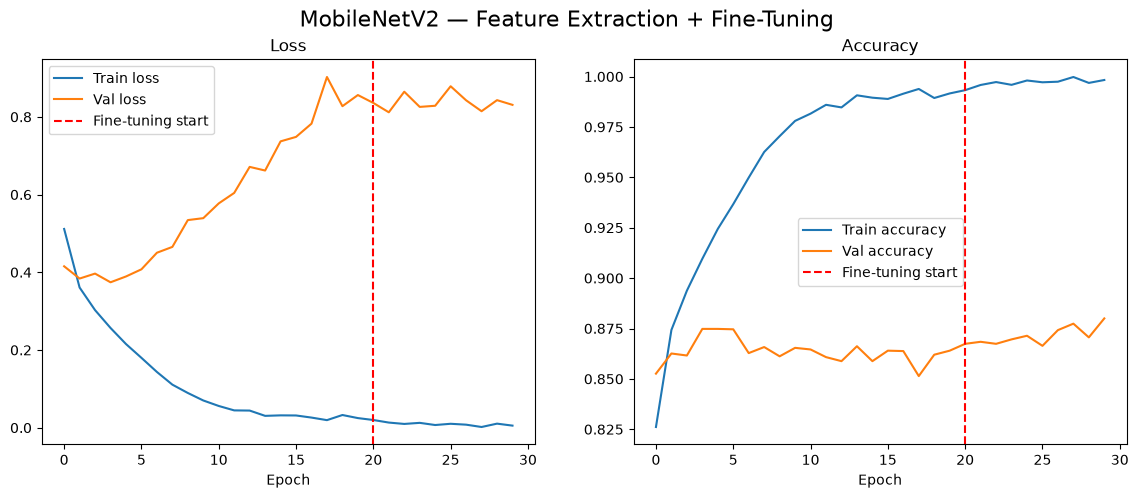

In [165]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_loss, label='Train loss')
axes[0].plot(val_loss, label='Val loss')
axes[0].set_title('Loss')

axes[1].plot(train_acc, label='Train accuracy')
axes[1].plot(val_acc, label='Val accuracy')
axes[1].set_title('Accuracy')

for ax in axes:
    ax.axvline(ft_start, color='red', linestyle='--', label='Fine-tuning start')
    ax.set_xlabel('Epoch')
    ax.legend()

fig.suptitle('MobileNetV2 — Feature Extraction + Fine-Tuning', fontsize=16)
plt.savefig(plots_dir + '/finetuning_curves.png', bbox_inches='tight')
plt.show()

- Left of the red line: only the new head is trained.
- Right of the red line: the top base layers are trained too, with a very small learning rate.
- A small learning rate protects the good pre-trained weights.

### A6.5 Results comparison

In [166]:
import pandas as pd

In [167]:
model_names = ['LeNet-5', 'CNN Scratch (No Aug)', 'CNN Scratch + Aug', 'CNN + Keras Aug Layers',
               'MobileNetV2 Feature Extraction', 'MobileNetV2 Fine-Tuned']

In [168]:
architectures = ['LeNet-5 (tanh + AvgPool)', 'Custom CNN', 'Custom CNN', 'Custom CNN',
                 'MobileNetV2 (frozen) + Dense head',
                 'MobileNetV2 (top layers unfrozen) + Dense head']
augmentations = ['No', 'No', 'ImageDataGenerator', 'Keras layers', 'No', 'No']
transfer = ['No', 'No', 'No', 'No', 'Feature Extraction', 'Fine-Tuning']

In [169]:
accuracies = [lenet_acc, test_acc, aug_acc, layers_acc, fe_acc, ft_acc]

In [170]:
parameters = [model_lenet.count_params(), model_cnn.count_params(),
              model_aug.count_params(), model_layers.count_params(),
              total_params, total_params]

In [171]:
results_df = pd.DataFrame({
    'Model': model_names,
    'Architecture': architectures,
    'Augmentation': augmentations,
    'Transfer Learning': transfer,
    'Test Accuracy': np.round(accuracies, 4),
    'Parameters': parameters
})

In [172]:
results_df.style.highlight_max(subset=['Test Accuracy'], color='lightgreen')

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5 (tanh + AvgPool),No,No,0.547600,62006
1,CNN Scratch (No Aug),Custom CNN,No,No,0.787900,175018
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,0.828400,175018
3,CNN + Keras Aug Layers,Custom CNN,Keras layers,No,0.784300,175018
4,MobileNetV2 Feature Extraction,MobileNetV2 (frozen) + Dense head,No,Feature Extraction,0.853000,2423242
5,MobileNetV2 Fine-Tuned,MobileNetV2 (top layers unfrozen) + Dense head,No,Fine-Tuning,0.872600,2423242


In [173]:
best_index = np.argmax(accuracies)
print('Best model        :', model_names[best_index])
print('Best test accuracy:', round(accuracies[best_index], 4))

Best model        : MobileNetV2 Fine-Tuned
Best test accuracy: 0.8726


In [174]:
results_df.to_csv('results_table.csv', index=False)

- Green cell is the best test accuracy.
- Transfer learning gives high accuracy with less training effort.
- A custom CNN needs more epochs and augmentation to improve.

### A6.6 Residual connection

In [175]:
res_filters = 64

In [176]:
inputs = keras.Input(shape=input_shape)

In [177]:
shortcut = keras.layers.Conv2D(res_filters, 1, padding='same')(inputs)

In [178]:
x = keras.layers.Conv2D(res_filters, kernel_size, activation='relu', padding='same')(inputs)
x = keras.layers.Conv2D(res_filters, kernel_size, activation='relu', padding='same')(x)

In [179]:
x = keras.layers.Add()([shortcut, x])
outputs = keras.layers.Activation('relu')(x)

In [180]:
model_res = keras.Model(inputs, outputs)

In [181]:
model_res.summary()

Model: "model_4"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_7 (InputLayer)        [(None, 32, 32, 3)]          0         []                            
                                                                                                  
 conv2d_26 (Conv2D)          (None, 32, 32, 64)           1792      ['input_7[0][0]']             
                                                                                                  
 conv2d_25 (Conv2D)          (None, 32, 32, 64)           256       ['input_7[0][0]']             
                                                                                                  
 conv2d_27 (Conv2D)          (None, 32, 32, 64)           36928     ['conv2d_26[0][0]']           
                                                                                            

- The shortcut adds the input directly to the output of the conv layers.
- Gradients can flow through the shortcut, which helps very deep networks train.

## Final Interpretation

In [ ]:
print('Best model:', model_names[best_index])
print('Scratch CNN accuracy:', round(test_acc, 4))
print('Best accuracy       :', round(accuracies[best_index], 4))

- A CNN uses small shared filters, so it needs far fewer parameters than a normal ANN.
- The scratch CNN is a good baseline, but it can overfit.
- Augmentation gives more image variety and usually reduces the train–val gap.
- Transfer learning usually gives the best score with the least training, because the model already knows image features.
- A residual connection helps deeper networks train.